# Before, During, and After Training: Traditional Initialization vs. Xavier

We compare **traditional initialization** (`old`): $U(-1/\sqrt{fan_{in}}, 1/\sqrt{fan_{in}})$ with **Xavier initialization**: $U(-\sqrt{6/(fan_{in}+fan_{out})}, +\sqrt{6/(fan_{in}+fan_{out})})$.

For `tanh`, `sigmoid`, `ReLU`, and `LeakyReLU`, we track **MSE**, **weight gradient L2 norms**, and **activation standard deviations**. Measurements are taken **before training (epoch 0), after every epoch, and at the end (epoch EPOCHS)**, using the *same* fixed probe dataset. Measurements do not update the weights.


In [2]:
import math
import torch
from torch import nn
import matplotlib.pyplot as plt


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.set_num_threads(1)
SEED, DEPTH, WIDTH, EPOCHS = 42, 12, 64, 35

torch.manual_seed(SEED)
X = torch.randn(2000, 20)
y = (torch.sin(X[:, 0]) + 0.5 * X[:, 1] * X[:, 2]).unsqueeze(1)
X_train, X_val = X[:1600], X[1600:]
y_train, y_val = y[:1600], y[1600:]
X_probe, y_probe = X_train[:256], y_train[:256]

activations = {
    'tanh': nn.Tanh,
    'sigmoid': nn.Sigmoid,
    'ReLU': nn.ReLU,
    'LeakyReLU': lambda: nn.LeakyReLU(0.1),
}



## 1. Build the neural network


In [3]:
def make_model(activation, init):
    torch.manual_seed(SEED)
    layers = []
    sizes = [20] + [WIDTH] * DEPTH + [1]
    for i in range(len(sizes) - 1):
        linear = nn.Linear(sizes[i], sizes[i + 1])
        if init == 'xavier':
            nn.init.xavier_uniform_(linear.weight)
        else:
            bound = 1 / math.sqrt(sizes[i])
            nn.init.uniform_(linear.weight, -bound, bound)
        nn.init.zeros_(linear.bias)
        layers.append(linear)
        if i < DEPTH:
            layers.append(activation())
    return nn.Sequential(*layers)

## 2. Measure statistics on a fixed probe dataset

`gradients` contains the L2 norms of weight gradients in the **12 hidden layers**. `stds` contains the standard deviations of their activations. Gradient measurement requires calling `backward()`, but we **do not call** `optimizer.step()` during measurement.


In [4]:
def measure(model):
    model.eval()
    model.zero_grad()
    output = X_probe
    stds = []
    for layer in model:
        output = layer(output)
        if isinstance(layer, (nn.Tanh, nn.Sigmoid, nn.ReLU, nn.LeakyReLU)):
            stds.append(output.detach().std().item())

    loss = nn.functional.mse_loss(output, y_probe)
    loss.backward()
    linears = [layer for layer in model if isinstance(layer, nn.Linear)]
    gradients = [layer.weight.grad.norm().item() for layer in linears[:-1]]
    model.zero_grad()
    return gradients, stds

## 3. Train the model and collect metrics


In [5]:
def experiment(activation, init):
    model = make_model(activation, init)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    grads, stds = measure(model)  # epoch 0: before training
    result = {'grads': [grads], 'stds': [stds], 'mse': []}

    with torch.no_grad():
        result['mse'].append(nn.functional.mse_loss(model(X_val), y_val).item())

    for epoch in range(EPOCHS):
        model.train()
        for xb, yb in zip(X_train.split(128), y_train.split(128)):
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(xb), yb)
            loss.backward()
            optimizer.step()

        grads, stds = measure(model)  # measurement after each epoch
        result['grads'].append(grads)
        result['stds'].append(stds)
        with torch.no_grad():
            result['mse'].append(nn.functional.mse_loss(model(X_val), y_val).item())
    return result

results = {}
for name, activation in activations.items():
    for init in ['old', 'xavier']:
        results[name, init] = experiment(activation, init)
        print(f'{name:10s} {init:6s} MSE: {results[name, init]["mse"][-1]:.4f}')

tanh       old    MSE: 0.2002
tanh       xavier MSE: 0.1155
sigmoid    old    MSE: 0.6643
sigmoid    xavier MSE: 0.4608
ReLU       old    MSE: 0.0692
ReLU       xavier MSE: 0.1174
LeakyReLU  old    MSE: 0.0990
LeakyReLU  xavier MSE: 0.0833


## 4. Learning curves — validation MSE


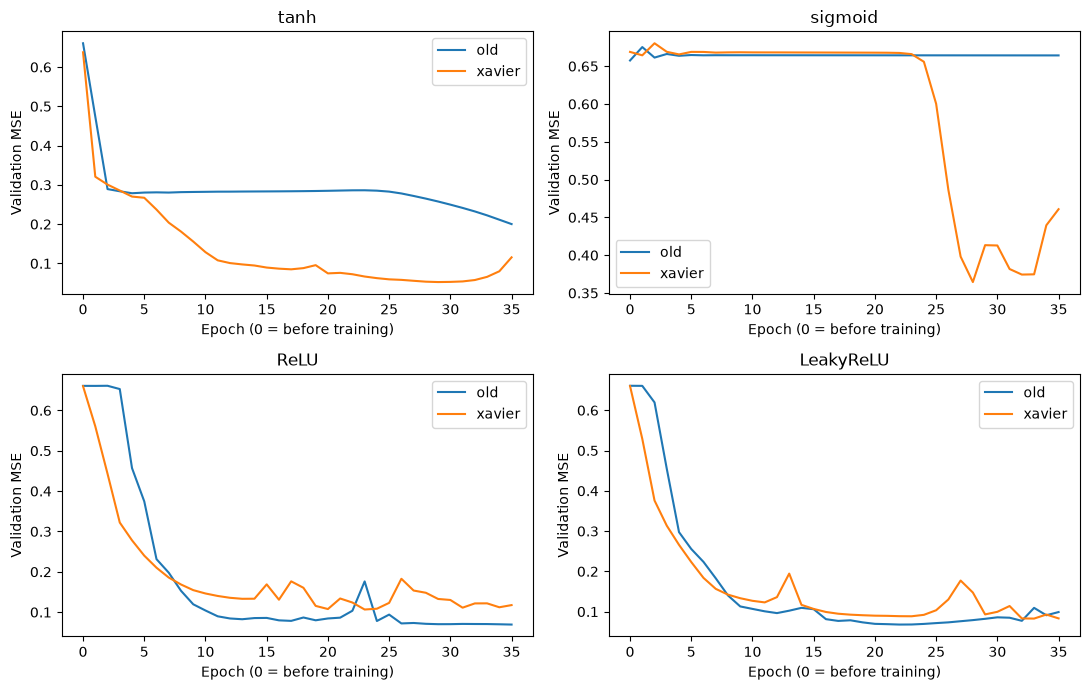

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.flat, activations):
    for init in ['old', 'xavier']:
        ax.plot(range(EPOCHS + 1), results[name, init]['mse'], label=init)
    ax.set(title=name, xlabel='Epoch (0 = before training)', ylabel='Validation MSE')
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Per-layer gradients: before, halfway through, and after training

The y-axis uses a logarithmic scale. Very small gradients in earlier layers may indicate vanishing gradients. Gradient norms are not a direct measure of learning quality.


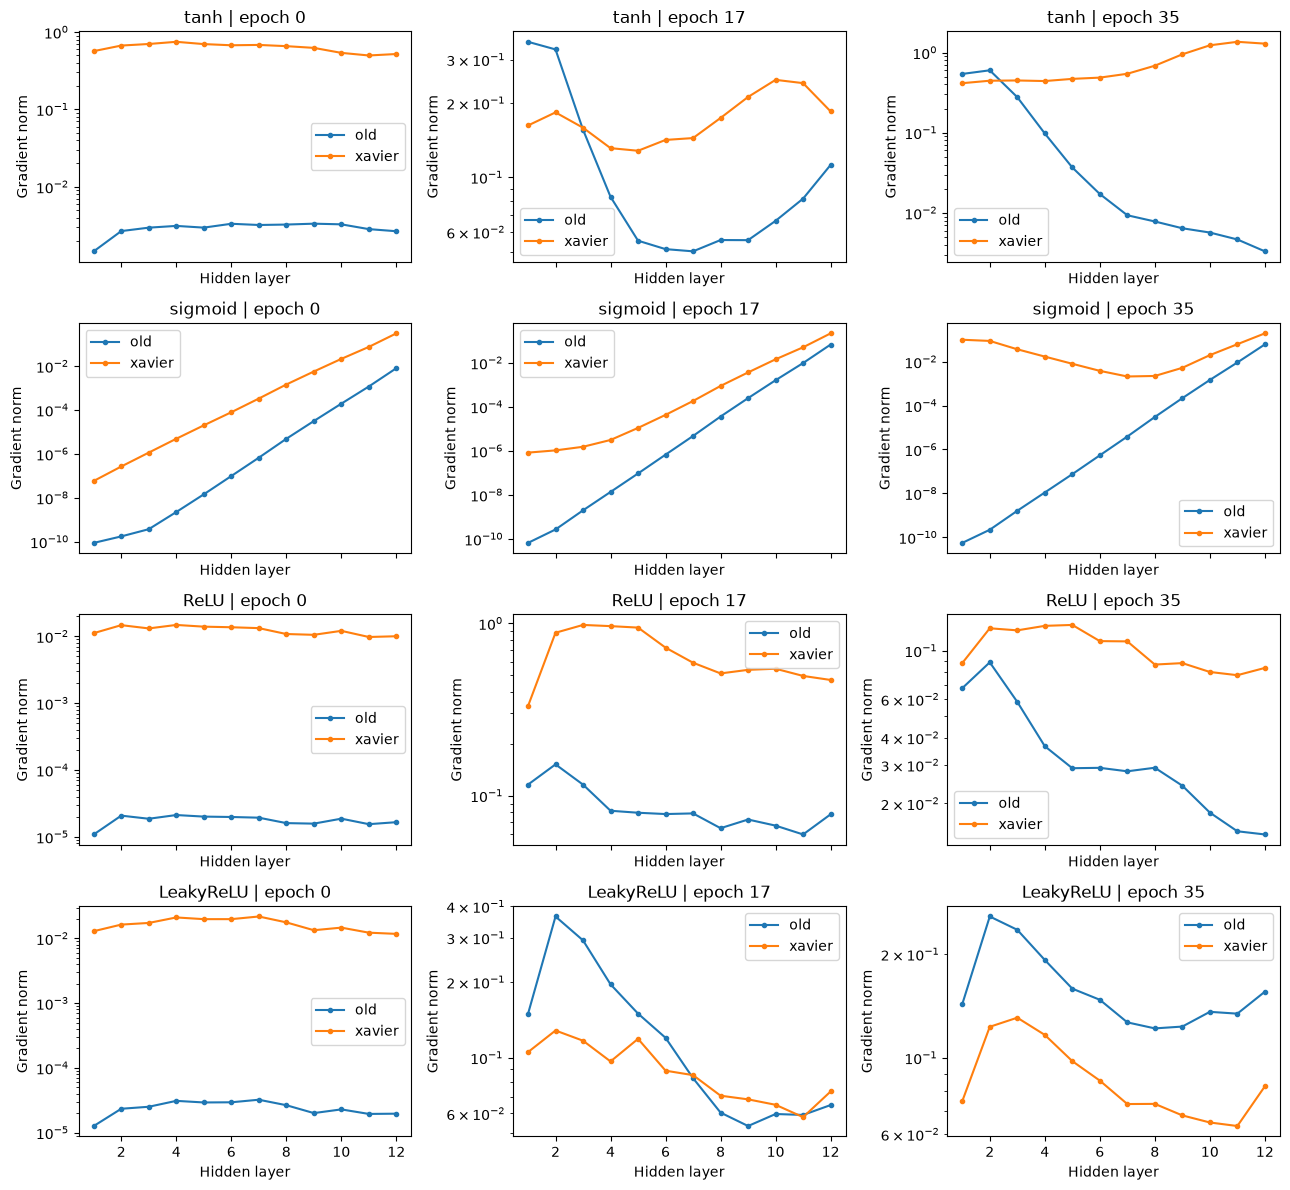

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(13, 12), sharex=True)
checkpoints = [0, EPOCHS // 2, EPOCHS]
for row, name in enumerate(activations):
    for col, epoch in enumerate(checkpoints):
        ax = axes[row, col]
        for init in ['old', 'xavier']:
            g = results[name, init]['grads'][epoch]
            ax.semilogy(range(1, DEPTH + 1), g, marker='.', label=init)
        ax.set(title=f'{name} | epoch {epoch}', xlabel='Hidden layer', ylabel='Gradient norm')
        ax.legend()
plt.tight_layout()
plt.show()

## 6. How does the first layer’s gradient change during training?


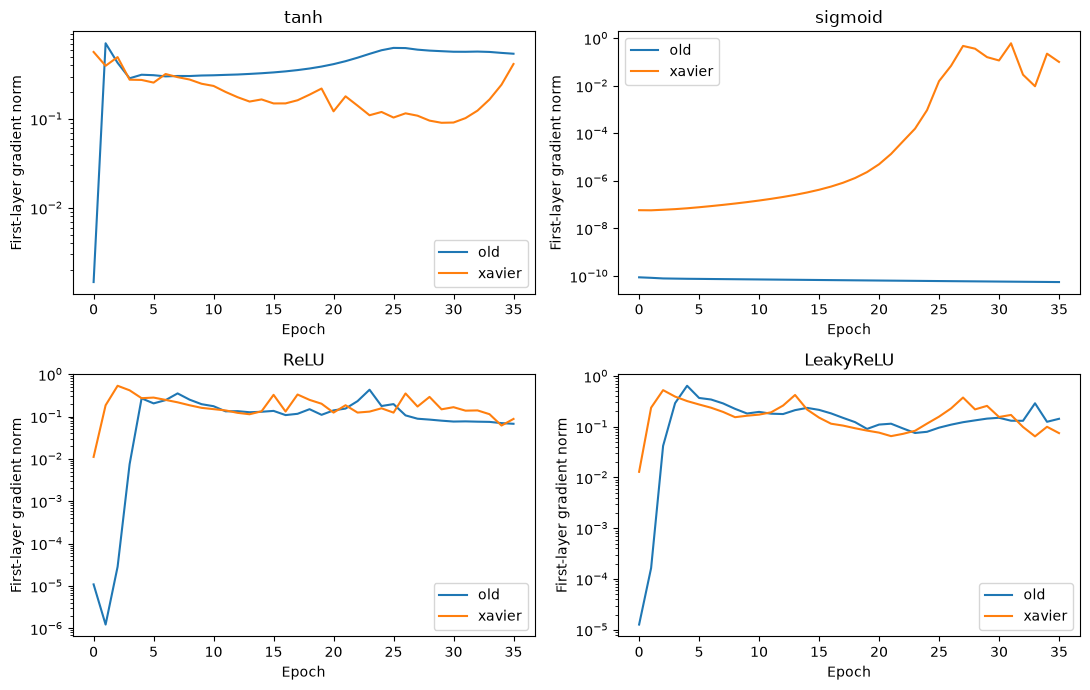

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.flat, activations):
    for init in ['old', 'xavier']:
        first = [row[0] for row in results[name, init]['grads']]
        ax.semilogy(range(EPOCHS + 1), first, label=init)
    ax.set(title=name, xlabel='Epoch', ylabel='First-layer gradient norm')
    ax.legend()
plt.tight_layout()
plt.show()

## 7. How does activation scale change across layers?

The standard deviation of post-activation outputs indicates whether the signal loses variability in deeper layers. It **does not directly measure saturation**; for sigmoid, interpret it alongside the gradients.


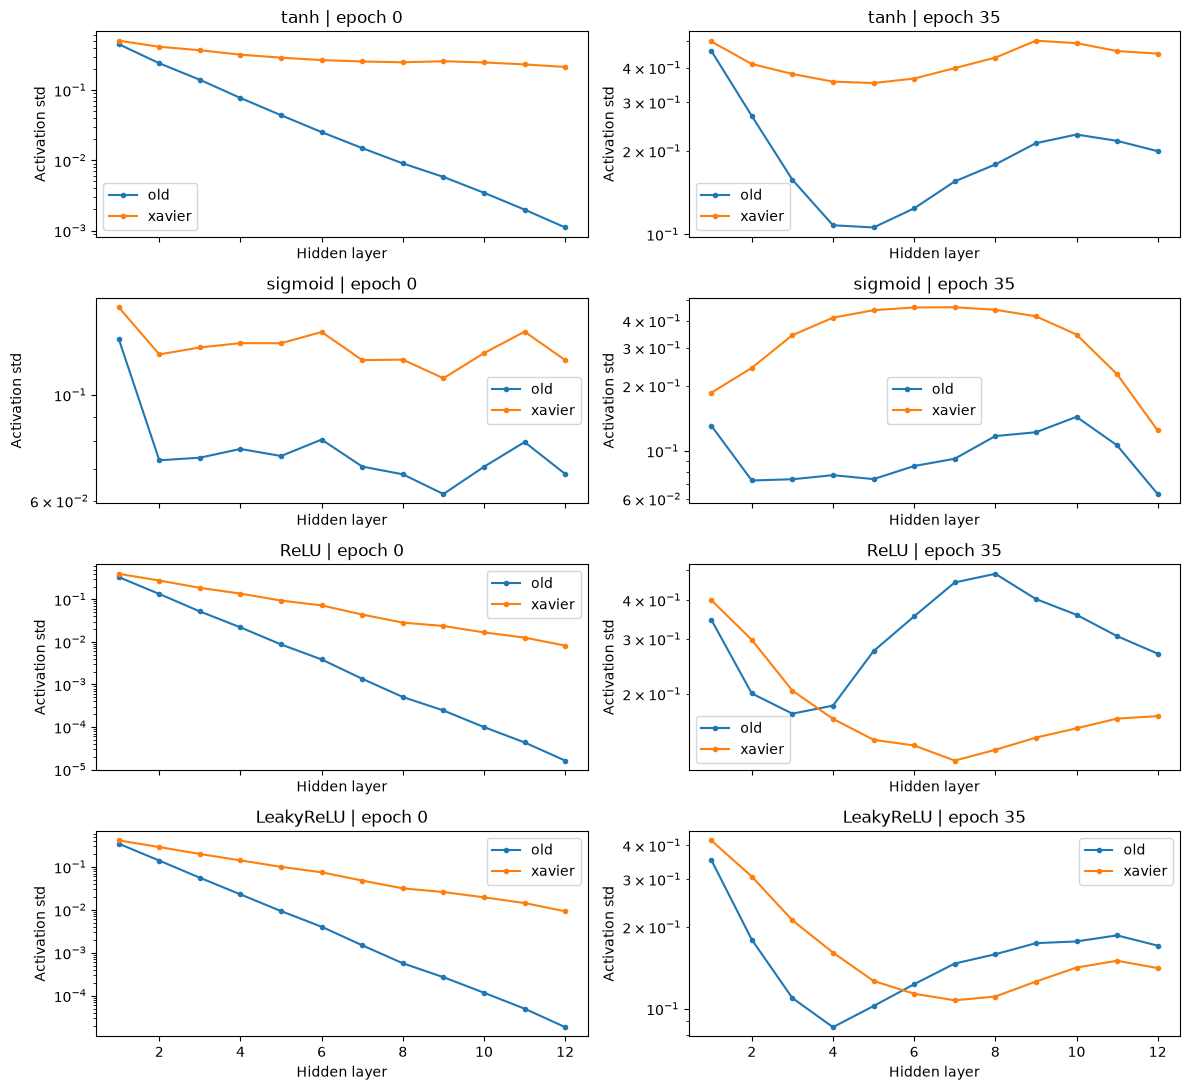

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
for row, name in enumerate(activations):
    for col, epoch in enumerate([0, EPOCHS]):
        ax = axes[row, col]
        for init in ['old', 'xavier']:
            ax.semilogy(range(1, DEPTH + 1), results[name, init]['stds'][epoch], marker='.', label=init)
        ax.set(title=f'{name} | epoch {epoch}', xlabel='Hidden layer', ylabel='Activation std')
        ax.legend()
plt.tight_layout()
plt.show()

## How to interpret the results

- Compare `old` and `xavier` **within the same activation function**.
- Look for small gradient norms in early layers relative to later ones, especially **before training**, and observe how this changes over time.
- `tanh` often benefits from Xavier, but `sigmoid` can still suffer from vanishing gradients. For `ReLU`, Xavier is not always ideal (He initialization exists, but is intentionally excluded here).
- This is an educational experiment using synthetic data, **not an exact reproduction** of the paper. A single random seed and learning rate cannot establish that one method is universally better.
